In [1]:
import sys

# Setup

In [2]:
# To add your own Drive Run this cell.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Please append your own directory after ‘/content/drive/My Drive/'
# where you have nutil.py and adult_subsample.csv
### ========== TODO : START ========== ###
sys.path += ['/content/drive/My Drive/CS M146']
sys.path += ['/content/drive/']

### ========== TODO : END ========== ###


In [6]:
from nutil import *

In [7]:
# Use only the provided packages!
import math
import csv

from collections import Counter

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit
import numpy as np
import warnings
warnings.filterwarnings('ignore', category=np.VisibleDeprecationWarning)

# Models

In [8]:
######################################################################
# Immutatble classes
######################################################################

class Classifier(object) :
    """
    Classifier interface.
    """

    def fit(self, X, y):
        raise NotImplementedError()

    def predict(self, X):
        raise NotImplementedError()


class MajorityVoteClassifier(Classifier) :

    def __init__(self) :
        """
        A classifier that always predicts the majority class.

        Attributes
        --------------------
            prediction_ -- majority class
        """
        self.prediction_ = None

    def fit(self, X, y) :
        """
        Build a majority vote classifier from the training set (X, y).

        Parameters
        --------------------
            X    -- numpy array of shape (n,d), samples
            y    -- numpy array of shape (n,), target classes

        Returns
        --------------------
            self -- an instance of self
        """
        majority_val = Counter(y).most_common(1)[0][0]
        self.prediction_ = majority_val
        return self

    def predict(self, X) :
        """
        Predict class values.

        Parameters
        --------------------
            X    -- numpy array of shape (n,d), samples

        Returns
        --------------------
            y    -- numpy array of shape (n,), predicted classes
        """
        if self.prediction_ is None :
            raise Exception("Classifier not initialized. Perform a fit first.")

        n,d = X.shape
        y = [self.prediction_] * n
        return y



In [9]:
######################################################################
# Mutatble classes
######################################################################

class RandomClassifier(Classifier) :

    def __init__(self) :
        """
        A classifier that predicts according to the distribution of the classes.

        Attributes
        --------------------
            probabilities_ -- class distribution dict (key = class, val = probability of class)
        """
        self.probabilities_ = None

    def fit(self, X, y) :
        """
        Build a random classifier from the training set (X, y).

        Parameters
        --------------------
            X    -- numpy array of shape (n,d), samples
            y    -- numpy array of shape (n,), target classes

        Returns
        --------------------
            self -- an instance of self
        """

        ### ========== TODO : START ========== ###
        # part b: set self.probabilities_ according to the training set
        counts = Counter(y)
        total = sum(counts.values())
        self.probabilities_ = Counter({c: f / total for c, f in counts.items()})

        ### ========== TODO : END ========== ###

        return self

    def predict(self, X, seed=1234) :
        """
        Predict class values.

        Parameters
        --------------------
            X    -- numpy array of shape (n,d), samples
            seed -- integer, random seed

        Returns
        --------------------
            y    -- numpy array of shape (n,), predicted classes
        """
        if self.probabilities_ is None :
            raise Exception("Classifier not initialized. Perform a fit first.")
        np.random.seed(seed)

        ### ========== TODO : START ========== ###
        # part b: predict the class for each test example
        # hint: use np.random.choice (be careful of the parameters)
        y = np.random.choice(list(self.probabilities_.keys()), size = X.shape[0], p = list(self.probabilities_.values()))

        ### ========== TODO : END ========== ###

        return y


# Auxiliary functions

In [10]:
######################################################################
# Immutatble functions
######################################################################

def plot_histograms(X, y, Xnames, yname) :
    n,d = X.shape  # n = number of examples, d =  number of features
    fig = plt.figure(figsize=(20,15))
    ncol = 3
    nrow = d // ncol + 1
    for i in range(d) :
        fig.add_subplot (nrow,ncol,i+1)
        data, bins, align, labels = plot_histogram(X[:,i], y, Xname=Xnames[i], yname=yname, show = False)
        n, bins, patches = plt.hist(data, bins=bins, align=align, alpha=0.5, label=labels)
        plt.xlabel(Xnames[i])
        plt.ylabel('Frequency')
        plt.legend() #plt.legend(loc='upper left')

    plt.savefig ('histograms.pdf')


def plot_histogram(X, y, Xname, yname, show = True) :
    """
    Plots histogram of values in X grouped by y.

    Parameters
    --------------------
        X     -- numpy array of shape (n,d), feature values
        y     -- numpy array of shape (n,), target classes
        Xname -- string, name of feature
        yname -- string, name of target
    """

    # set up data for plotting
    targets = sorted(set(y))
    data = []; labels = []
    for target in targets :
        features = [X[i] for i in range(len(y)) if y[i] == target]
        data.append(features)
        labels.append('%s = %s' % (yname, target))

    # set up histogram bins
    features = set(X)
    nfeatures = len(features)
    test_range = list(range(int(math.floor(min(features))), int(math.ceil(max(features)))+1))
    if nfeatures < 10 and sorted(features) == test_range:
        bins = test_range + [test_range[-1] + 1] # add last bin
        align = 'left'
    else :
        bins = 10
        align = 'mid'

    # plot
    if show == True:
        plt.figure()
        n, bins, patches = plt.hist(data, bins=bins, align=align, alpha=0.5, label=labels)
        plt.xlabel(Xname)
        plt.ylabel('Frequency')
        plt.legend() #plt.legend(loc='upper left')
        plt.show()

    return data, bins, align, labels

In [11]:
######################################################################
# Mutatble functions
######################################################################

def error(clf, X, y, ntrials=100, test_size=0.2) :
    """
    Computes the classifier error over a random split of the data,
    averaged over ntrials runs.

    Parameters
    --------------------
        clf         -- classifier
        X           -- numpy array of shape (n,d), features values
        y           -- numpy array of shape (n,), target classes
        ntrials     -- integer, number of trials

    Returns
    --------------------
        train_error -- float, training error
        test_error  -- float, test error
        f1_score    -- float, test "micro" averaged f1 score
    """

    ### ========== TODO : START ========== ###
    # compute cross-validation error using StratifiedShuffleSplit over ntrials
    train_error = 0.0
    test_error = 0.0
    f1_score = 0.0

    sss = StratifiedShuffleSplit(n_splits = ntrials, test_size = test_size, random_state = 0)
    for train_idx, test_idx in sss.split(X,y):
      X_train, X_test = X[train_idx], X[test_idx]
      y_train, y_test = y[train_idx], y[test_idx]
      clf.fit(X_train, y_train)
      y_pred_train = clf.predict(X_train)
      y_pred_test = clf.predict(X_test)
      tr_error = 1 - metrics.accuracy_score(y_train, y_pred_train, normalize=True)

      te_error = 1 - metrics.accuracy_score(y_test, y_pred_test, normalize=True)
      # te_error = np.mean(1 - cross_val_score(clf, X_test, y_test, cv=10, scoring='accuracy'))

      f1 = metrics.f1_score(y_test, y_pred_test, average='micro')

      train_error += tr_error
      test_error += te_error
      f1_score += f1

    train_error /= ntrials
    test_error /= ntrials
    f1_score /= ntrials

    ### ========== TODO : END ========== ###

    return train_error, test_error, f1_score

In [12]:
######################################################################
# Immutatble functions
######################################################################


def write_predictions(y_pred, filename, yname=None) :
    """Write out predictions to csv file."""
    out = open(filename, 'wb')
    f = csv.writer(out)
    if yname :
        f.writerow([yname])
    f.writerows(list(zip(y_pred)))
    out.close()

# Evaluation

Plotting...


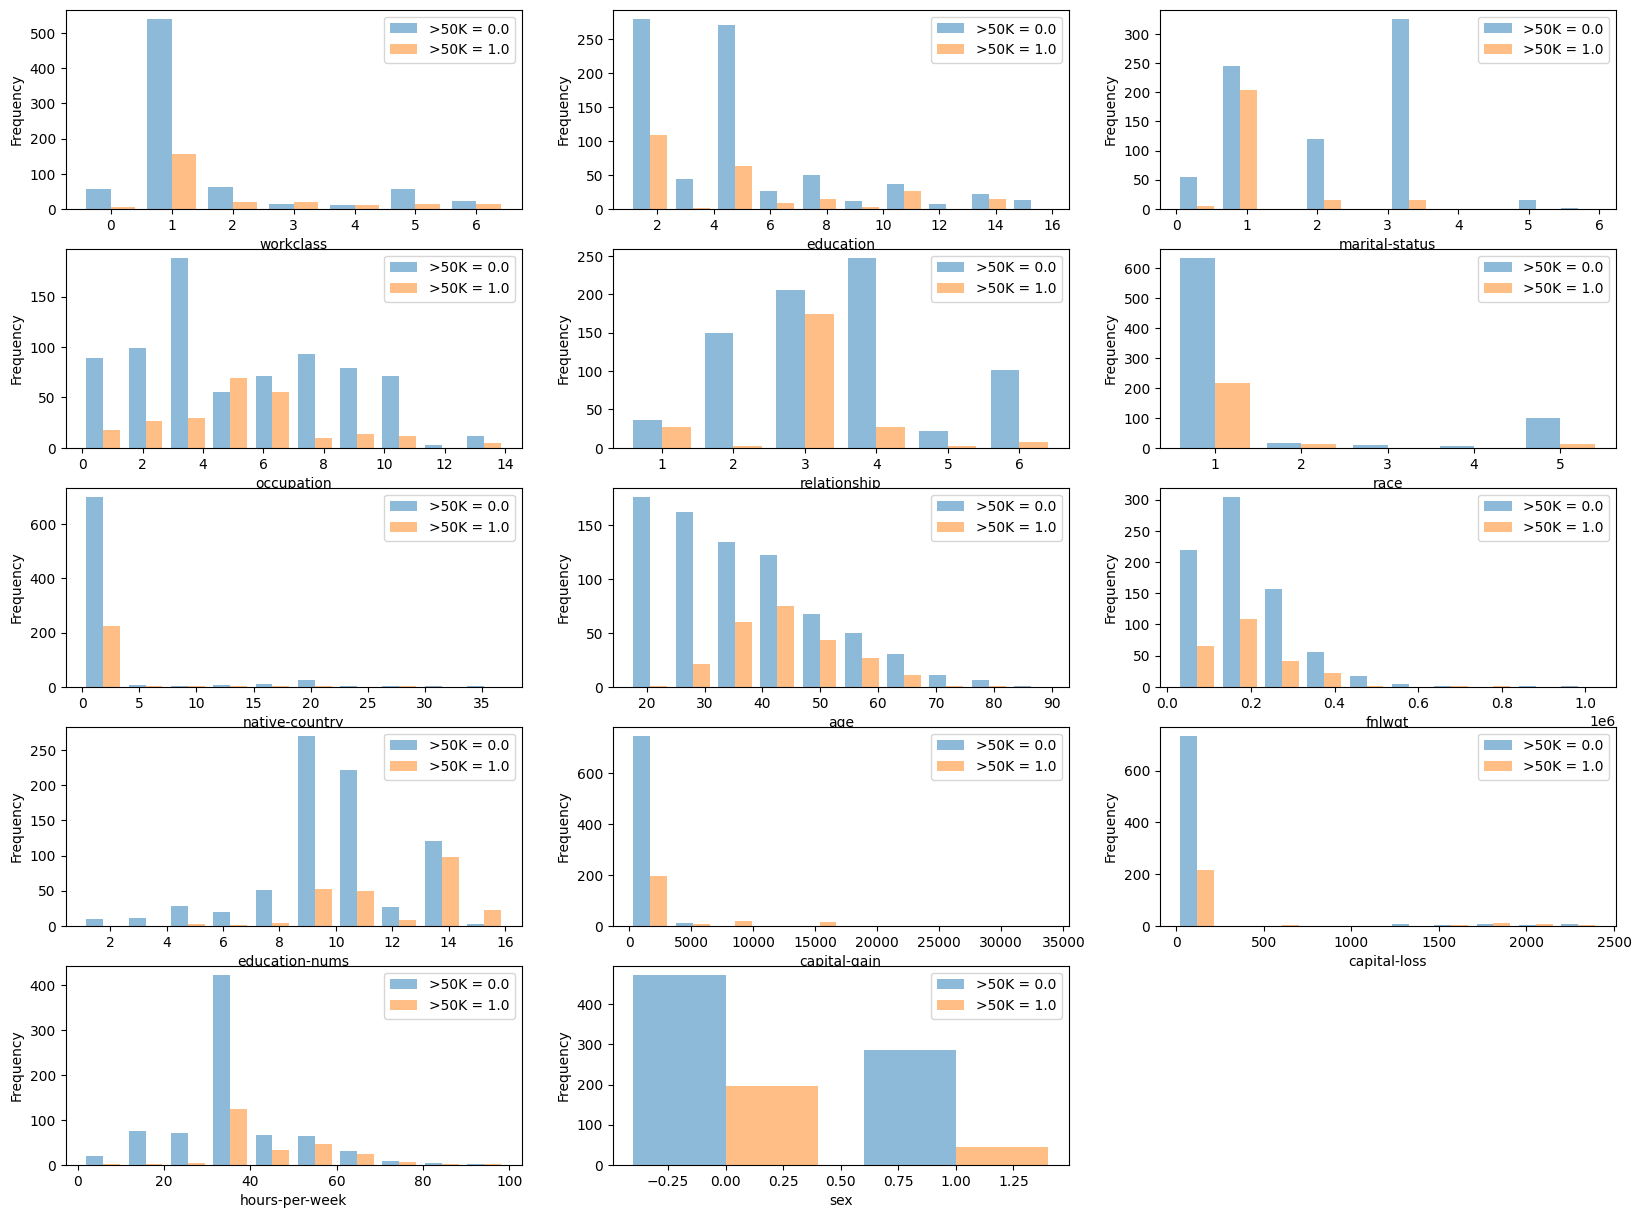

Classifying using Majority Vote...
	-- training error: 0.240
Classifying using Random...
	-- training error: 0.385
Classifying using Decision Tree...
	-- training error: 0.000
Classifying using k-Nearest Neighbors...
for 3 neighbors: 
	-- training error: 0.114
for 5 neighbors: 
	-- training error: 0.129
for 7 neighbors: 
	-- training error: 0.152
Investigating various classifiers...
Majority Vote Classifier train_error, test_error, f1_score: 
(0.2399999999999996, 0.2399999999999996, 0.7600000000000002)
Random Classifier train_error, test_error, f1_score: 
(0.3717750000000002, 0.3733999999999997, 0.6266000000000003)
Decision Tree Classifier train_error, test_error, f1_score: 
(0.0, 0.21119999999999986, 0.7888000000000001)
KN Neighbors Classifier train_error, test_error, f1_score: 
(0.13265000000000002, 0.20900000000000005, 0.7910000000000004)
Finding the best k...


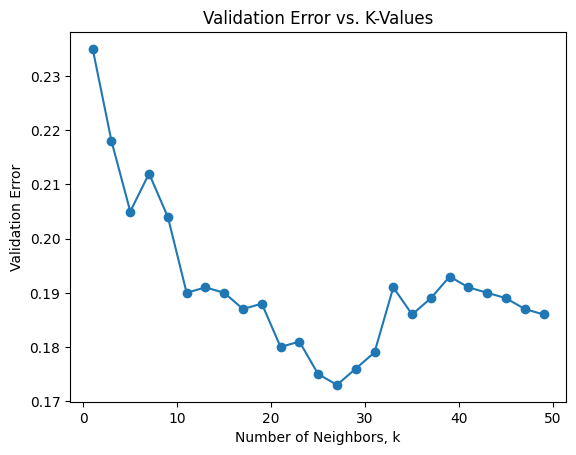

Investigating depths...


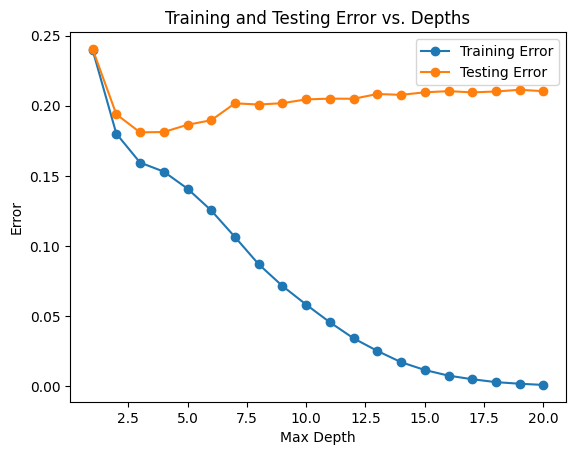

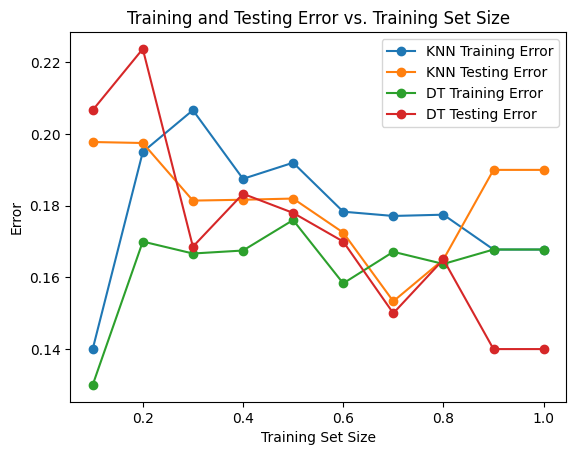

Done


In [18]:
######################################################################
# main
######################################################################

def main():
    # load adult_subsample dataset with correct file path
    ### ========== TODO : START ========== ###
    data_file =  "/content/drive/My Drive/CS M146/adult_subsample.csv"
    ### ========== TODO : END ========== ###


    data = load_data(data_file, header=1, predict_col=-1)

    X = data.X; Xnames = data.Xnames
    y = data.y; yname = data.yname
    n,d = X.shape  # n = number of examples, d =  number of features




    #========================================
    # part a: plot histograms of each feature
    print('Plotting...')
    plot_histograms (X, y, Xnames=Xnames, yname=yname)
    plt.show()



    ### ========== TODO : START ========== ###
    # part i: Preprocess X (e.g., normalize)
    # (try this after finishing the sections below)

    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    ### ========== TODO : END ========== ###




    #========================================
    # train Majority Vote classifier on data
    print('Classifying using Majority Vote...')
    clf = MajorityVoteClassifier() # create MajorityVote classifier, which includes all model parameters
    clf.fit(X, y)                  # fit training data using the classifier
    y_pred = clf.predict(X)        # take the classifier and run it on the training data
    train_error = 1 - metrics.accuracy_score(y, y_pred, normalize=True)
    print('\t-- training error: %.3f' % train_error)





    ### ========== TODO : START ========== ###
    # part b: evaluate training error of Random classifier
    print('Classifying using Random...')
    clf = RandomClassifier()
    clf.fit(X, y)
    y_pred = clf.predict(X)
    train_error = 1 - metrics.accuracy_score(y, y_pred, normalize=True)

    print('\t-- training error: %.3f' % train_error)
    ### ========== TODO : END ========== ###




    ### ========== TODO : START ========== ###
    # part c: evaluate training error of Decision Tree classifier
    print('Classifying using Decision Tree...')
    clf = DecisionTreeClassifier(criterion='entropy')
    clf.fit(X, y)
    y_pred = clf.predict(X)
    train_error = 1 - metrics.accuracy_score(y, y_pred, normalize=True)
    print('\t-- training error: %.3f' % train_error)
    ### ========== TODO : END ========== ###




    ### ========== TODO : START ========== ###
    # part d: evaluate training error of k-Nearest Neighbors classifier
    # use k = 3, 5, 7 for n_neighbors
    print('Classifying using k-Nearest Neighbors...')
    for k in [3,5,7]:
      clf = KNeighborsClassifier(n_neighbors = k)
      clf.fit(X,y)
      y_pred = clf.predict(X)
      train_error = 1 - metrics.accuracy_score(y, y_pred, normalize=True)
      print(f'for {k} neighbors: ')
      print('\t-- training error: %.3f' % train_error)

    # print the error for each k


    ### ========== TODO : END ========== ###




    ### ========== TODO : START ========== ###
    # part e: use cross-validation to compute average training and test error of classifiers
    print('Investigating various classifiers...')

    clf = MajorityVoteClassifier()
    summary = error(clf, X, y, ntrials=100)
    print("Majority Vote Classifier train_error, test_error, f1_score: ")
    print(summary)

    clf = RandomClassifier()
    summary = error(clf, X, y, ntrials=100)
    print("Random Classifier train_error, test_error, f1_score: ")
    print(summary)

    clf = DecisionTreeClassifier()
    summary = error(clf, X, y, ntrials=100)
    print("Decision Tree Classifier train_error, test_error, f1_score: ")
    print(summary)

    clf = KNeighborsClassifier(n_neighbors=5)
    summary = error(clf, X, y, ntrials=100)
    print("KN Neighbors Classifier train_error, test_error, f1_score: ")
    print(summary)

    # summary = error(clf, X, y, ntrials=20)
    # print(summary)
    ### ========== TODO : END ========== ###




    ### ========== TODO : START ========== ###
    # part f: use 10-fold cross-validation to find the best value of k for k-Nearest Neighbors classifier
    print('Finding the best k...')
    k_values = list(range(1, 51, 2))
    val_error = []
    for k in k_values:
      clf = KNeighborsClassifier(n_neighbors = k)
      scores = cross_val_score(estimator=clf, X=X, y=y, cv=10)
      val_error.append(np.mean(1 - scores))

    plt.plot(k_values, val_error, marker='o')
    plt.xlabel('Number of Neighbors, k')
    plt.ylabel('Validation Error')
    plt.title('Validation Error vs. K-Values')
    plt.show()

    ### ========== TODO : END ========== ###




    ### ========== TODO : START ========== ###
    # part g: investigate decision tree classifier with various depths
    print('Investigating depths...')
    depths = list(range(1, 21))
    train_error = []
    test_error = []
    for d in depths:
      clf = DecisionTreeClassifier(max_depth=d)
      scores = error(clf, X, y, ntrials=100)
      train_error.append(scores[0])
      test_error.append(scores[1])

    plt.plot(depths, train_error, label='Training Error',marker='o')
    plt.plot(depths, test_error, label='Testing Error',marker='o')
    plt.legend()
    plt.xlabel('Max Depth')
    plt.ylabel('Error')
    plt.title('Training and Testing Error vs. Depths')
    plt.show()


    ### ========== TODO : END ========== ###





    ### ========== TODO : START ========== ###
    # part h: investigate decision tree and k-Nearest Neighbors classifier with various training set sizes
    # hint: use train_test_split (use random_state=0 for consistent results)
    from sklearn.model_selection import train_test_split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0)
    knn_train_error = []
    knn_test_error = []
    dt_train_error = []
    dt_test_error = []

    for i in np.arange(0.1,1.1,0.1):
      if i == 1.0:
        X_train_subset = X_train
        X_test_subset = X_test
        y_train_subset = y_train
        y_test_subset = y_test
      else:
        X_train_subset, X_test_subset, y_train_subset, y_test_subset = train_test_split(X, y, train_size=i, random_state=0)

      knnclf = KNeighborsClassifier(n_neighbors=15)
      knnclf.fit(X_train_subset, y_train_subset)
      y_pred_train_knn = knnclf.predict(X_train_subset)
      y_pred_test_knn = knnclf.predict(X_test_subset)

      knn_train_error.append(1 - metrics.accuracy_score(y_train_subset, y_pred_train_knn, normalize=True))
      knn_test_error.append(1 - metrics.accuracy_score(y_test_subset, y_pred_test_knn, normalize=True))

      dtclf = DecisionTreeClassifier(max_depth=3)
      dtclf.fit(X_train_subset, y_train_subset)
      y_pred_train_dt = dtclf.predict(X_train_subset)
      y_pred_test_dt = dtclf.predict(X_test_subset)

      dt_train_error.append(1 - metrics.accuracy_score(y_train_subset, y_pred_train_dt, normalize=True))
      dt_test_error.append(1 - metrics.accuracy_score(y_test_subset, y_pred_test_dt, normalize=True))


    plt.plot(np.arange(0.1,1.1,0.1), knn_train_error, label='KNN Training Error',marker='o')
    plt.plot(np.arange(0.1,1.1,0.1), knn_test_error, label='KNN Testing Error',marker='o')

    plt.plot(np.arange(0.1,1.1,0.1), dt_train_error, label='DT Training Error',marker='o')
    plt.plot(np.arange(0.1,1.1,0.1), dt_test_error, label='DT Testing Error',marker='o')

    plt.legend()

    plt.xlabel('Training Set Size')
    plt.ylabel('Error')
    plt.title('Training and Testing Error vs. Training Set Size')
    plt.show()
    ### ========== TODO : END ========== ###



    print('Done')


if __name__ == "__main__":
    main()
